# 💾 Lưu Trữ, Tải Lại & Đánh Giá Mô Hình Tối Ưu (Model Serialization & Inference)
> **Đề tài:** Hệ Thống Gợi Ý Chiến Lược Học Tập Cá Nhân Hóa (KLTN 13 - HUIT)  
> **Mục tiêu:** Huấn luyện mô hình tốt nhất với đặc trưng tối ưu từ **HCO-VNLS**, đóng gói lưu trữ (`.joblib` / `.json`), tải lại và kiểm thử độc lập phục vụ tích hợp API Backend.

---  
### 📌 Các Giai Đoạn Chính:
1. **Huấn luyện & Lựa chọn đặc trưng:** Sử dụng thuật toán cải tiến HCO-VNLS để tìm tập đặc trưng tối ưu.
2. **Đóng gói Artifacts (Serialization):** Lưu model, pipeline tiền xử lý, danh sách đặc trưng và benchmarks chuẩn vào `packages/ml/artifacts/`.
3. **Tải lại Model (Deserialization / Serving Simulation):** Nạp lại toàn bộ thành phần trong một ngữ cảnh hoàn toàn mới.
4. **Kiểm thử & Đánh giá (Sanity Check & Verification):** Kiểm tra tính nhất quán dự báo, vẽ Confusion Matrix và ROC Curve.
5. **Mô phỏng Suy luận Thực tế (Real-Time Inference Demo):** Dự báo nguy cơ và sinh chiến lược can thiệp cho hồ sơ sinh viên mới.

In [1]:
import os
import sys
import time
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score, roc_curve
)

# Thêm thư mục gốc vào đường dẫn hệ thống
sys.path.append(os.path.abspath('..'))

from packages.ml.src.preprocessing.pipeline import DataPipeline
from packages.ml.src.optimization.hco_vnls import HCOVNLS
from packages.ml.src.models.recommendation.engine import LearningRecommendationEngine

# Cấu hình trực quan hóa
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.sans-serif'] = 'Segoe UI'
print('Đã nạp toàn bộ các thư viện thành công!')

C:\Users\NGUYEN\AppData\Local\Programs\Python\Python312\Lib\site-packages\seaborn\_statistics.py:32: UserWarning: A NumPy version >=1.23.5 and <2.3.0 is required for this version of SciPy (detected version 2.5.2)
  from scipy.stats import gaussian_kde


Đã nạp toàn bộ các thư viện thành công!


## 1. Huấn Luyện Mô Hình Với Đặc Trưng Tối Ưu Từ Thuật Toán HCO-VNLS

In [2]:
# 1. Nạp dữ liệu
data_path = '../data/processed/oulad_features_engineered.csv'
df_data = pd.read_csv(data_path)
print(f'Tổng số mẫu dữ liệu: {df_data.shape[0]} | Số cột: {df_data.shape[1]}')

# 2. Tiền xử lý
pipeline = DataPipeline(target_col='final_result', binary_target=True)
X, y, feature_names = pipeline.fit_transform(df_data)

# 3. Phân chia Train / Test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y.values, test_size=0.2, random_state=42, stratify=y.values
)

# 4. Chạy tối ưu hóa HCO-VNLS để chọn tập đặc trưng tốt nhất
print('Đang thực thi thuật toán cải tiến HCO-VNLS để chọn đặc trưng...')
hco_vnls = HCOVNLS(pop_size=20, max_iter=20, alpha=0.85, k_max_vnls=4, vnls_interval=2, random_state=42)
best_mask, best_fit, history = hco_vnls.optimize(X_train[:4000], y_train[:4000])

selected_indices = np.where(best_mask == 1)[0]
selected_feature_names = [feature_names[i] for i in selected_indices]
print(f'✅ Tập đặc trưng tối ưu ({len(selected_feature_names)}/{len(feature_names)} đặc trưng):')
for idx, fname in enumerate(selected_feature_names, 1):
    print(f'   {idx:02d}. {fname}')

# 5. Huấn luyện mô hình Random Forest tối ưu
best_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=1)
best_model.fit(X_train[:, selected_indices], y_train)

# 6. Đánh giá sơ bộ trên tập kiểm thử
y_test_pred = best_model.predict(X_test[:, selected_indices])
y_test_prob = best_model.predict_proba(X_test[:, selected_indices])[:, 1]
print(f'\nKết quả kiểm thử ban đầu: Accuracy = {accuracy_score(y_test, y_test_pred):.4f} | ROC-AUC = {roc_auc_score(y_test, y_test_prob):.4f}')

Tổng số mẫu dữ liệu: 32593 | Số cột: 33


Đang thực thi thuật toán cải tiến HCO-VNLS để chọn đặc trưng...


✅ Tập đặc trưng tối ưu (3/30 đặc trưng):
   01. total_assessments_taken
   02. weighted_avg_score
   03. clicks_late



Kết quả kiểm thử ban đầu: Accuracy = 0.9239 | ROC-AUC = 0.9735


## 2. Đóng Gói và Lưu Trữ Artifacts (Model Serialization)
Lưu các thành phần sau vào thư mục `packages/ml/artifacts/`:
- Mô hình phân loại tối ưu (`best_hco_vnls_model.joblib`)
- Pipeline tiền xử lý & chuẩn hóa (`data_pipeline.joblib`)
- Thông tin cấu hình đặc trưng tối ưu (`selected_features.json`)
- Ngưỡng chuẩn đánh giá chiến lược học tập (`recommendation_benchmarks.json`)

In [3]:
artifacts_base = os.path.abspath('../packages/ml/artifacts')
models_dir = os.path.join(artifacts_base, 'models')
scalers_dir = os.path.join(artifacts_base, 'scalers')

os.makedirs(models_dir, exist_ok=True)
os.makedirs(scalers_dir, exist_ok=True)

# 1. Lưu Model
model_path = os.path.join(models_dir, 'best_hco_vnls_model.joblib')
joblib.dump(best_model, model_path)
print(f'✅ Đã lưu model: {model_path} ({os.path.getsize(model_path) / 1024:.1f} KB)')

# 2. Lưu Preprocessing Pipeline
pipeline_path = os.path.join(scalers_dir, 'data_pipeline.joblib')
joblib.dump(pipeline, pipeline_path)
print(f'✅ Đã lưu pipeline: {pipeline_path} ({os.path.getsize(pipeline_path) / 1024:.1f} KB)')

# 3. Lưu Selected Features Mask & Names
features_info = {
    'all_feature_names': feature_names,
    'selected_indices': selected_indices.tolist(),
    'selected_feature_names': selected_feature_names,
    'binary_mask': best_mask.tolist(),
    'best_fitness': float(best_fit),
    'num_features_selected': len(selected_feature_names),
    'total_features': len(feature_names)
}
features_path = os.path.join(models_dir, 'selected_features.json')
with open(features_path, 'w', encoding='utf-8') as f:
    json.dump(features_info, f, indent=2, ensure_ascii=False)
print(f'✅ Đã lưu danh sách đặc trưng: {features_path}')

# 4. Khởi tạo & Lưu Recommendation Engine Benchmarks
rec_engine = LearningRecommendationEngine(feature_names=feature_names, feature_mask=best_mask)
rec_engine.fit_benchmarks(df_data, y)

benchmarks_path = os.path.join(models_dir, 'recommendation_benchmarks.json')
with open(benchmarks_path, 'w', encoding='utf-8') as f:
    json.dump(rec_engine.benchmark_medians, f, indent=2, ensure_ascii=False)
print(f'✅ Đã lưu benchmarks gợi ý: {benchmarks_path}')

✅ Đã lưu model: Y:\study\sv4_hk1\kltn13-personalized-learning-recommendation\packages\ml\artifacts\models\best_hco_vnls_model.joblib (5745.8 KB)
✅ Đã lưu pipeline: Y:\study\sv4_hk1\kltn13-personalized-learning-recommendation\packages\ml\artifacts\scalers\data_pipeline.joblib (5.5 KB)
✅ Đã lưu danh sách đặc trưng: Y:\study\sv4_hk1\kltn13-personalized-learning-recommendation\packages\ml\artifacts\models\selected_features.json
✅ Đã lưu benchmarks gợi ý: Y:\study\sv4_hk1\kltn13-personalized-learning-recommendation\packages\ml\artifacts\models\recommendation_benchmarks.json


## 3. Tải Lại Model & Thành Phần Phục Vụ Suy Luận (Model Loading Phase)
Giả lập môi trường máy chủ Backend API: giải phóng các biến huấn luyện khỏi bộ nhớ và nạp lại từ ổ đĩa.

In [4]:
# Xóa các đối tượng trong bộ nhớ để đảm bảo tính độc lập
del best_model
del pipeline
del rec_engine

print('--- ĐANG NẠP LẠI CÁC THÀNH PHẦN TỪ ARTIFACTS ---')

# 1. Nạp Model
loaded_model = joblib.load(model_path)
print('1. Nạp model thành công:', type(loaded_model).__name__)

# 2. Nạp Pipeline
loaded_pipeline = joblib.load(pipeline_path)
print('2. Nạp pipeline thành công:', type(loaded_pipeline).__name__)

# 3. Nạp Cấu hình Đặc trưng
with open(features_path, 'r', encoding='utf-8') as f:
    loaded_feat_info = json.load(f)
loaded_mask = np.array(loaded_feat_info['binary_mask'])
loaded_indices = np.array(loaded_feat_info['selected_indices'])
print(f'3. Nạp danh sách đặc trưng thành công ({len(loaded_indices)} đặc trưng)')

# 4. Nạp Recommendation Engine
loaded_rec_engine = LearningRecommendationEngine(
    feature_names=loaded_feat_info['all_feature_names'],
    feature_mask=loaded_mask
)
with open(benchmarks_path, 'r', encoding='utf-8') as f:
    loaded_rec_engine.benchmark_medians = json.load(f)
print('4. Nạp recommendation engine thành công!')

--- ĐANG NẠP LẠI CÁC THÀNH PHẦN TỪ ARTIFACTS ---
1. Nạp model thành công: RandomForestClassifier
2. Nạp pipeline thành công: DataPipeline
3. Nạp danh sách đặc trưng thành công (3 đặc trưng)
4. Nạp recommendation engine thành công!


## 4. Kiểm Thử & Xác Thực Tính Nhất Quán Của Model Đã Nạp (Verification & Testing)

In [5]:
# Dự báo lại trên tập kiểm thử bằng mô hình đã nạp
X_test_selected = X_test[:, loaded_indices]
reloaded_preds = loaded_model.predict(X_test_selected)
reloaded_probs = loaded_model.predict_proba(X_test_selected)[:, 1]

# 1. Kiểm tra tính đồng nhất dự báo tuyệt đối (Sanity Check)
assert np.array_equal(reloaded_preds, y_test_pred), 'LỖI: Kết quả dự báo không khớp với model gốc!'
print('✅ Sanity Check PASSED: Kết quả dự báo của model sau khi nạp hoàn toàn khớp 100%!')

# 2. Các chỉ số phân loại chi tiết
acc = accuracy_score(y_test, reloaded_preds)
prec = precision_score(y_test, reloaded_preds, average='weighted')
rec = recall_score(y_test, reloaded_preds, average='weighted')
f1 = f1_score(y_test, reloaded_preds, average='weighted')
auc = roc_auc_score(y_test, reloaded_probs)

print('\n' + '='*55)
print('     KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH SAU KHI NẠP LẠI')
print('='*55)
print(f' Độ chính xác (Accuracy):       {acc*100:.2f}%')
print(f' Precision (Weighted):          {prec*100:.2f}%')
print(f' Recall (Weighted):             {rec*100:.2f}%')
print(f' F1-Score (Weighted):           {f1*100:.2f}%')
print(f' ROC-AUC Score:                 {auc:.4f}')
print('='*55)

print('\nBáo cáo phân loại (Classification Report):')
print(classification_report(y_test, reloaded_preds, target_names=['Nguy cơ (Fail/Withdrawn)', 'Thành công (Pass/Distinction)']))

✅ Sanity Check PASSED: Kết quả dự báo của model sau khi nạp hoàn toàn khớp 100%!



     KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH SAU KHI NẠP LẠI
 Độ chính xác (Accuracy):       92.39%
 Precision (Weighted):          92.62%
 Recall (Weighted):             92.39%
 F1-Score (Weighted):           92.40%
 ROC-AUC Score:                 0.9735

Báo cáo phân loại (Classification Report):
                               precision    recall  f1-score   support

     Nguy cơ (Fail/Withdrawn)       0.96      0.90      0.93      3442
Thành công (Pass/Distinction)       0.89      0.96      0.92      3077

                     accuracy                           0.92      6519
                    macro avg       0.92      0.93      0.92      6519
                 weighted avg       0.93      0.92      0.92      6519



### 4.1. Trực Quan Hóa Ma Trận Nhầm Lẫn & Đường Cong ROC

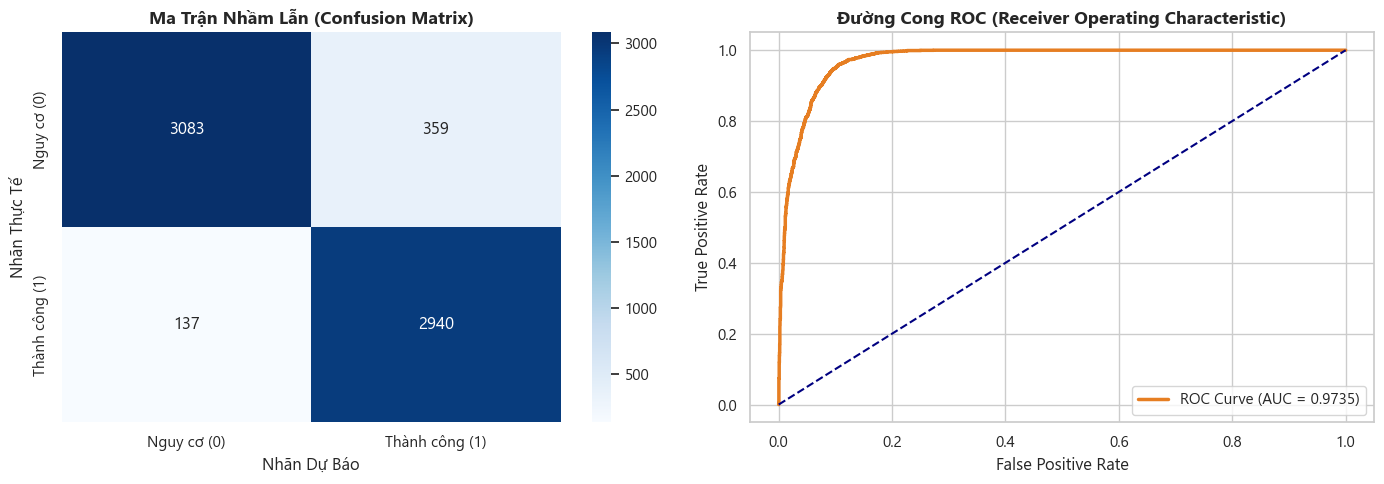

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Confusion Matrix
cm = confusion_matrix(y_test, reloaded_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Nguy cơ (0)', 'Thành công (1)'],
            yticklabels=['Nguy cơ (0)', 'Thành công (1)'])
axes[0].set_title('Ma Trận Nhầm Lẫn (Confusion Matrix)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Nhãn Dự Báo')
axes[0].set_ylabel('Nhãn Thực Tế')

# 2. ROC Curve
fpr, tpr, _ = roc_curve(y_test, reloaded_probs)
axes[1].plot(fpr, tpr, color='#e67e22', lw=2.5, label=f'ROC Curve (AUC = {auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--')
axes[1].set_title('Đường Cong ROC (Receiver Operating Characteristic)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

## 5. Mô Phỏng Quy Trình Suy Luận Thời Gian Thực (End-to-End Inference Demo)
Nhập một hồ sơ sinh viên mới dạng Dictionary / JSON (chưa qua tiền xử lý), thực hiện biến đổi $ightarrow$ dự báo nguy cơ $ightarrow$ sinh lộ trình gợi ý can thiệp cá nhân hóa.

In [7]:
# Giả lập hồ sơ sinh viên mới cần chẩn đoán
new_student_raw = {
    'code_module': 'BBB',
    'code_presentation': '2013J',
    'id_student': 999999,
    'gender': 'M',
    'region': 'South Region',
    'highest_education': 'A Level or Equivalent',
    'imd_band': '20-30%',
    'age_band': '0-35',
    'num_of_prev_attempts': 1,
    'studied_credits': 60,
    'disability': 'N',
    'date_registration': -20.0,
    'avg_score': 42.5,
    'min_score': 35.0,
    'max_score': 50.0,
    'std_score': 7.5,
    'total_assessments_taken': 2,
    'late_submissions': 1,
    'weighted_avg_score': 41.8,
    'total_clicks': 180,
    'active_days': 14,
    'clicks_early': 45,
    'clicks_mid': 95,
    'clicks_late': 40,
    'clicks_forumng': 15,
    'clicks_oucontent': 60,
    'clicks_resource': 30,
    'clicks_subpage': 20,
    'clicks_url': 10,
    'clicks_homepage': 40,
    'clicks_quiz': 5
}

# Chuyển thành DataFrame đơn lẻ
df_single = pd.DataFrame([new_student_raw])

# 1. Tiền xử lý bằng Pipeline đã load
X_single = loaded_pipeline.transform(df_single)

# 2. Trích xuất đặc trưng tối ưu
X_single_selected = X_single[:, loaded_indices]

# 3. Dự báo xác suất rủi ro bằng Model đã load
risk_proba = float(loaded_model.predict_proba(X_single_selected)[0, 0])  # Xác suất rủi ro (Class 0: Fail/Withdrawn)
predicted_class = int(loaded_model.predict(X_single_selected)[0])

# 4. Sinh gợi ý cá nhân hóa
recommendation_result = loaded_rec_engine.generate_student_recommendations(
    student_data=new_student_raw,
    predicted_risk_prob=risk_proba
)

print('='*75)
print('   BÁO CÁO CHẨN ĐOÁN & GỢI Ý CHIẾN LƯỢC HỌC TẬP CÁ NHÂN HÓA')
print('='*75)
print(f'Mã sinh viên:        {new_student_raw["id_student"]}')
print(f'Mã môn học / Học kỳ: {new_student_raw["code_module"]} ({new_student_raw["code_presentation"]})')
print(f'Đánh giá rủi ro:     {recommendation_result["status_text"]}')
print(f'Xác suất nguy cơ:    {risk_proba * 100:.2f}%')
print('='*75)

print('\n❌ CÁC YẾU TỐ RỦI RO PHÁT HIỆN:')
for w in recommendation_result['weaknesses']:
    print(f'  • {w}')

print('\n💡 CHIẾN LƯỢC HỌC TẬP ĐỀ XUẤT CỤ THỂ:')
for idx, item in enumerate(recommendation_result['strategies'], 1):
    print(f'  {idx}. [{item["priority"]}] {item["category"]}:')
    print(f'     👉 Hành động: {item["action"]}')
    print(f'     🎯 Mục tiêu:  {item["target_metric"]}')
print('='*75)

   BÁO CÁO CHẨN ĐOÁN & GỢI Ý CHIẾN LƯỢC HỌC TẬP CÁ NHÂN HÓA
Mã sinh viên:        999999
Mã môn học / Học kỳ: BBB (2013J)
Đánh giá rủi ro:     NGUY CƠ BỎ HỌC / RỚT MÔN CAO (HIGH RISK)
Xác suất nguy cơ:    100.00%

❌ CÁC YẾU TỐ RỦI RO PHÁT HIỆN:
  • Điểm số bài tập quá thấp (< 50 điểm)
  • Có 1 bài nộp trễ hạn
  • Mức độ chuyên cần trên hệ thống thấp (14 ngày hoạt động)

💡 CHIẾN LƯỢC HỌC TẬP ĐỀ XUẤT CỤ THỂ:
  1. [HIGH] Củng cố kiến thức nền tảng:
     👉 Hành động: Xem lại tài nguyên giảng dạy cốt lõi (oucontent) các tuần trước và làm lại các bài tập trắc nghiệm ngắn tự luyện.
     🎯 Mục tiêu:  Nâng điểm trung bình từ 42.5 lên trên 70.0 điểm.
  2. [HIGH] Quản lý thời gian & Hạn chót:
     👉 Hành động: Lập lịch biểu cá nhân hóa, đặt mốc hoàn thành trước hạn nộp chính thức 48 giờ để kịp rà soát bài nộp.
     🎯 Mục tiêu:  Giảm số lần trễ hạn về 0 bài.
  3. [HIGH] Độ chuyên cần & Tính liên tục:
     👉 Hành động: Tạo thói quen đăng nhập LMS tối thiểu 4 ngày/tuần, mỗi phiên ít nhất 30-45 phút.
